# Electron beam energy deposition: beam-pipe heating and FLASH dose

This notebook walks through the calculations in `backend/beamUtility.py` for two separate questions:

* **Case A - beam pipe / dump.** A defocused beam strikes a stainless-steel surface. How much of the beam power is absorbed by the wall, how much escapes as bremsstrahlung or passes through, and how hot does the surface get per macropulse?
* **Case B - FLASH radiotherapy.** A focused or unfocused beam enters a water or skin target that is much thinner than the electron range. What dose is delivered per macropulse and per bunch, at what dose rate, and how many pulses are needed for a prescription?

All stopping powers, CSDA ranges and radiation yields come from the **NIST ESTAR** tables stored in `backend/data/estar/` (downloaded 2026-09-21). An analytic Bethe formula is included only as an independent cross-check. The physics, assumptions and formulas are summarised in `docs/ENERGY_DEPOSITION.md`.

**Read the limits before quoting numbers.** The transport is CSDA (continuous slowing down): no multiple scattering, no range straggling, no lateral spreading in the target and no backscatter. This is accurate when the target is thin compared with the range (the FLASH case) and adequate for the energy bookkeeping of a wall or dump away from grazing incidence (Section 3 explains where it fails). Heating is adiabatic per macropulse; thermal conduction between pulses is not modelled.

In [1]:
import sys, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate backend/ whether the notebook is run from backend/examples, backend/ or the repo root.
BACKEND = Path.cwd().resolve()
for cand in [BACKEND, BACKEND.parent, BACKEND / "backend", BACKEND.parent / "backend"]:
    if (cand / "beamUtility.py").exists():
        BACKEND = cand
        break
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

import beamUtility as bu
from beamUtility import Beam, beam_pipe_heating, flash_dose, depth_dose, scan_beam_pipe, scan_flash

pd.set_option("display.float_format", "{:.4g}".format)  # 4 significant figures in every table, incl. mixed-type frames
pd.set_option("display.width", 140)
%matplotlib inline
print("beamUtility loaded from", BACKEND)
print("materials:", list(bu.MATERIALS))

beamUtility loaded from /Users/niels/Documents/GitHub/FELsim/backend
materials: ['Water', 'Skin', 'Soft Tissue', 'Aluminum', 'Copper', 'Iron', 'Stainless Steel']


## 1. Stopping power, range and radiation yield

For an electron of kinetic energy $E$ in a material of density $\rho$:

* **Collision (electronic) stopping power** $S_{col}/\rho$ [MeV cm²/g]: energy transferred to atomic electrons per unit mass thickness. This is the part that is deposited locally, i.e. the part that heats a wall or delivers dose to tissue.
* **Radiative stopping power** $S_{rad}/\rho$: energy converted to bremsstrahlung photons. For a thin wall these photons escape; for a thick dump a fraction is re-absorbed. It grows roughly linearly with $E$ and with $Z$. In the ESTAR tables it overtakes the collision term at about 24 MeV in copper, 27 MeV in iron and stainless steel, 51 MeV in aluminium and 91 MeV in water (the "critical energy" quoted in particle-physics tables uses a slightly different definition and is 10-20 % lower).
* **CSDA range** $R = \int_0^{E} dE'/S_{tot}(E')$ [g/cm²]: the path length travelled while slowing to rest. The straight-line penetration depth is smaller because of multiple scattering.
* **Radiation yield** $Y(E)$: fraction of the initial kinetic energy emitted as bremsstrahlung when the electron is completely stopped. For a thick target the absorbed fraction is $1 - Y(E)$.

Linear stopping power in MeV/cm is $\rho \cdot S/\rho$. In water the collision stopping power is almost flat above a few MeV (1.85 to 2.2 MeV cm²/g from 1 to 100 MeV), which is why the FLASH dose depends on charge and spot size, not on energy.

In [2]:
E_sel = [1, 5, 10, 20, 40, 100]
print("Water")
display(bu.stopping_power_table("Water", E_sel).set_index("Energy (MeV)"))
print("Stainless Steel (Bragg additivity of the Fe, Cr, Ni ESTAR tables)")
display(bu.stopping_power_table("Stainless Steel", E_sel).set_index("Energy (MeV)"))

Water


,S_col/rho (MeV cm2/g),S_rad/rho (MeV cm2/g),S_tot/rho (MeV cm2/g),S_col (MeV/cm),S_tot (MeV/cm),CSDA range (g/cm2),CSDA range (cm),Radiation yield
Energy (MeV),,,,,,,,
1,1.849,0.0128,1.862,1.849,1.862,0.4367,0.4367,0.003579
5,1.892,0.07917,1.971,1.892,1.971,2.55,2.55,0.01911
10,1.968,0.1814,2.149,1.968,2.149,4.975,4.975,0.04072
20,2.046,0.4086,2.455,2.046,2.455,9.32,9.32,0.08355
40,2.118,0.8955,3.013,2.118,3.013,16.65,16.65,0.1594
100,2.202,2.434,4.636,2.202,4.636,32.58,32.58,0.3192


Stainless Steel (Bragg additivity of the Fe, Cr, Ni ESTAR tables)


,S_col/rho (MeV cm2/g),S_rad/rho (MeV cm2/g),S_tot/rho (MeV cm2/g),S_col (MeV/cm),S_tot (MeV/cm),CSDA range (g/cm2),CSDA range (cm),Radiation yield
Energy (MeV),,,,,,,,
1,1.311,0.04133,1.352,10.35,10.68,0.6145,0.07778,0.01683
5,1.405,0.2332,1.639,11.1,12.94,3.32,0.4203,0.07308
10,1.485,0.5185,2.004,11.73,15.83,6.071,0.7684,0.138
20,1.562,1.138,2.7,12.34,21.33,10.35,1.31,0.2421
40,1.629,2.446,4.075,12.87,32.19,16.33,2.067,0.3817
100,1.707,6.547,8.254,13.48,65.21,26.47,3.351,0.5832


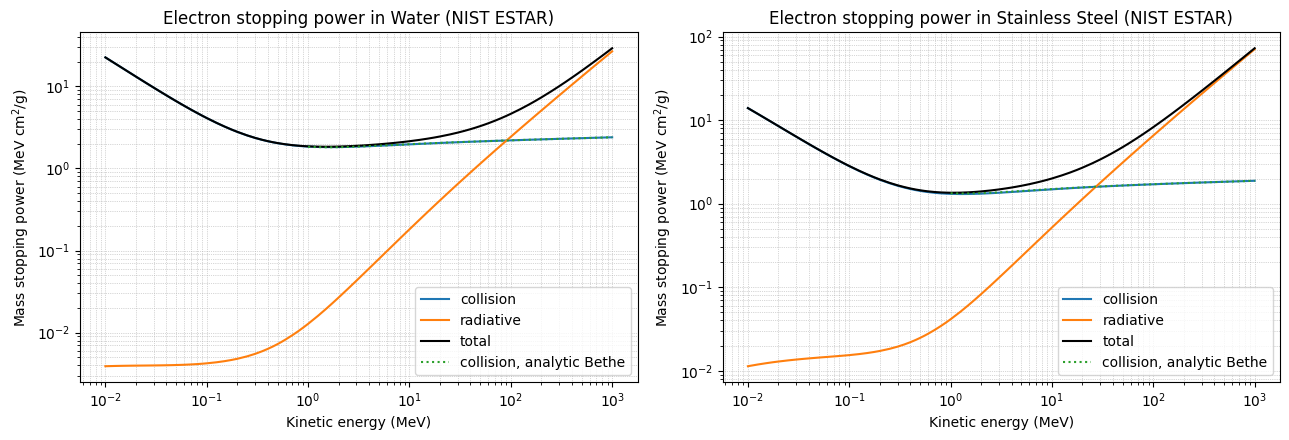

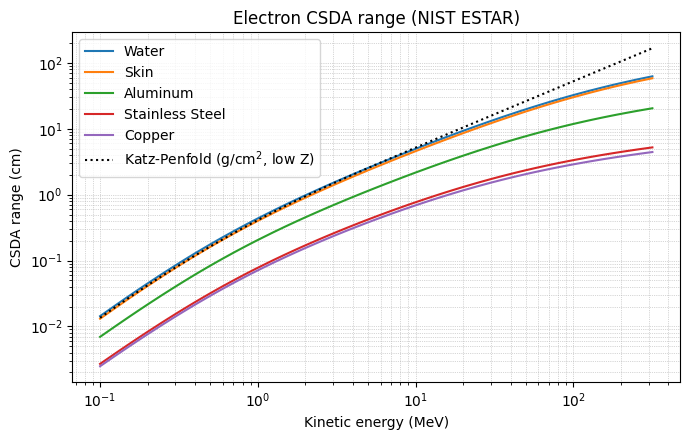

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bu.plot_stopping_power("Water", ax=axes[0], show=False)
bu.plot_stopping_power("Stainless Steel", ax=axes[1], show=False)
plt.tight_layout(); plt.show()

bu.plot_range(("Water", "Skin", "Aluminum", "Stainless Steel", "Copper"));

### Cross-check against the analytic Bethe formula

`bethe_collision_stopping_power` implements the Rohrlich-Carlson form of the Bethe formula for electrons (ICRU Report 37) with the Sternheimer density-effect correction. It is *not* used by the studies below; it is here to show that the tables and an independent formula agree, and to give a formula the student can derive by hand. Agreement is within 0.5 % for water and within a few percent for the alloys, where generic Sternheimer parameters are used.

In [4]:
print("Water"); display(bu.compare_with_estar("Water").set_index("Energy (MeV)"))
print("Stainless Steel"); display(bu.compare_with_estar("Stainless Steel").set_index("Energy (MeV)"))

Water


,ESTAR S_col/rho,Bethe S_col/rho,Ratio Bethe/ESTAR
Energy (MeV),,,
1,1.849,1.84,0.995
2,1.824,1.819,0.997
5,1.892,1.897,1.003
10,1.968,1.975,1.004
20,2.046,2.05,1.002
50,2.139,2.14,1.001
100,2.202,2.203,1


Stainless Steel


,ESTAR S_col/rho,Bethe S_col/rho,Ratio Bethe/ESTAR
Energy (MeV),,,
1,1.311,1.331,1.015
2,1.319,1.336,1.013
5,1.405,1.42,1.01
10,1.485,1.496,1.007
20,1.562,1.568,1.004
50,1.649,1.653,1.003
100,1.707,1.71,1.002


## 2. The beam

The S-band linac delivers **macropulses** of length $T$ at repetition rate $f_{rep}$, each containing bunches at $f_{bunch}$ = 2.856 GHz. With a macropulse current $I$:

* charge per macropulse $Q = I\,T$, number of electrons $N = Q/e$
* charge per bunch $Q_b = I / f_{bunch}$, bunches per macropulse $f_{bunch} T$
* average current $I\,T\,f_{rep}$ and average beam power $E\,I\,T\,f_{rep}$

The transverse size enters every local quantity (dose, surface heating) only through the **peak fluence** per macropulse. For a Gaussian beam with RMS sizes $\sigma_x, \sigma_y$

$$\Phi_{peak} = \frac{N}{2\pi\,\sigma_x\,\sigma_y}\,,$$

and for a uniform ellipse with semi-axes $a, b$, $\Phi = N/(\pi a b)$. Choosing a larger "beam area" such as $\pi(6\sigma_x)(6\sigma_y)$ would understate the peak fluence by a factor 18.

The nominal beam below is 40 MeV, 100 mA for 4 µs at 10 Hz with $\sigma_x$ = 1 mm and $\sigma_y$ = 10 mm at the target.

In [5]:
beam = Beam(energy_MeV=40.0, I_pulse_A=0.100, T_pulse_s=4e-6, f_rep_Hz=10.0,
            sigma_x_m=1e-3, sigma_y_m=10e-3, profile="gaussian")
pd.Series(beam.summary(), name="nominal beam").to_frame()

,nominal beam
Energy (MeV),40
Macropulse current (mA),100
Macropulse length (us),4
Rep rate (Hz),10
Charge per macropulse (nC),400
Charge per bunch (pC),35.01
Bunches per macropulse,1.142e+04
Electrons per macropulse,2.497e+12
Average current (uA),4
Beam power in pulse (MW),4


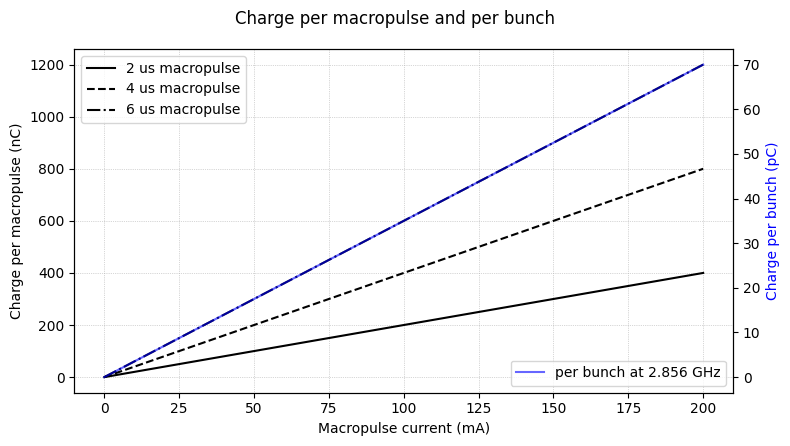

In [6]:
bu.plot_charge_per_macropulse(np.linspace(0, 0.2, 50), [2e-6, 4e-6, 6e-6], f_bunch_Hz=beam.f_bunch_Hz);

## 3. Case A: defocused beam on a stainless-steel beam pipe

`beam_pipe_heating(beam, material, wall_thickness_m, incidence_deg, brems_absorbed_fraction)`

Geometry and bookkeeping:

* The beam is **defocused** at the wall; below we use $\sigma_x$ = 5 mm, $\sigma_y$ = 20 mm.
* `incidence_deg` is the angle between the beam and the **wall normal**: 0° is a beam dump face, 80-89° is a beam grazing the inside of a pipe. The straight-line path in the wall is $t/\cos\theta$ and the footprint is stretched by $1/\cos\theta$, so the number of electrons per cm² of wall is $\Phi_{peak}\cos\theta$. Straight-line transport is least reliable at grazing incidence; see the discussion below the table.
* Along the path the code integrates $dE/ds = -\rho\,S_{tot}(E)$ and splits the initial energy into **collision** energy (deposited, heats the wall), **radiative** energy (bremsstrahlung; a fraction `brems_absorbed_fraction` is re-absorbed, 0 for a thin wall) and **transmitted** energy if the wall is thinner than the range.
* `wall_thickness_m=None` means a thick dump: the electron stops and the absorbed fraction is $1 - Y(E)$ from ESTAR.
* The **peak surface energy density** per macropulse is $\Phi_{peak}\,(S_{col}/\rho)(E_0)\times 1.602\times10^{-13}$ J/MeV, in J/g (= kGy), and the adiabatic temperature rise is $\Delta T = D / c_p$. It is **independent of the incidence angle**: the footprint stretch puts $\cos\theta$ fewer electrons on each cm² of wall, but each of them travels $1/\cos\theta$ further per unit depth, and the two factors cancel. What does depend on the angle is the energy per cm² of wall integrated over depth, i.e. the **absorbed power density** relevant for cooling. The macropulse (µs) is far shorter than any thermal diffusion time, so the adiabatic $\Delta T$ is the right per-pulse quantity. The "mean heating rate" ignores conduction and is an upper bound.

Neglected: backscatter (a few percent of the energy for steel near normal incidence) and multiple scattering inside the wall. The second matters at grazing incidence, see below; the module issues a warning above 75°.

In [7]:
wall_beam = Beam(energy_MeV=40.0, I_pulse_A=0.100, T_pulse_s=4e-6, f_rep_Hz=10.0,
                 sigma_x_m=5e-3, sigma_y_m=20e-3)

cases = {
    "thick dump, normal": beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=None, incidence_deg=0),
    "2 mm wall, normal":  beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=0),
    "2 mm wall, 80 deg":  beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=80),
    "2 mm wall, 88 deg":  beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=88),
}
pd.DataFrame(cases)

/var/folders/3h/pl9f2_4577n8tzvmr695cz2c0000gn/T/ipykernel_18628/2200561485.py:7: UserWarning: incidence_deg=80: straight-line (CSDA) transport is unreliable at grazing incidence; multiple scattering turns a large fraction of the electrons back out of the wall. Treat the deposited energy as an upper bound and use a Monte Carlo code.
  "2 mm wall, 80 deg":  beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=80),
/var/folders/3h/pl9f2_4577n8tzvmr695cz2c0000gn/T/ipykernel_18628/2200561485.py:8: UserWarning: incidence_deg=88: straight-line (CSDA) transport is unreliable at grazing incidence; multiple scattering turns a large fraction of the electrons back out of the wall. Treat the deposited energy as an upper bound and use a Monte Carlo code.
  "2 mm wall, 88 deg":  beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=88),


,"thick dump, normal","2 mm wall, normal","2 mm wall, 80 deg","2 mm wall, 88 deg"
Material,Stainless Steel,Stainless Steel,Stainless Steel,Stainless Steel
Energy (MeV),40,40,40,40
Wall thickness (mm),inf,2,2,2
Incidence from normal (deg),0,0,80,88
Path length in wall (mm),inf,2,11.52,57.31
CSDA range (mm),20.67,20.67,20.67,20.67
Electron stopped in wall,True,False,False,True
Energy deposited per electron (MeV),24.73,2.562,14.35,24.73
Energy radiated & escaping per electron (MeV),15.27,3.539,13.21,15.27
Energy transmitted per electron (MeV),0,33.9,12.44,0


### Effect of the incidence angle

In the straight-line model the path in a 2 mm wall, $t/\cos\theta$, exceeds the CSDA range (about 21 mm at 40 MeV) beyond about 84°, and the code then reports the electron as stopped with $E(1-Y)$ = 24.7 MeV deposited. **This is where the CSDA picture breaks down.** The RMS multiple-scattering angle of a 40 MeV electron in steel (Highland formula, $X_0 \approx 1.76$ cm) is already 2.8° after 0.5 mm of path, 6° after 2 mm and about 14° after 10 mm, comparable to or larger than the 10° and 2° grazing angles at 80° and 88° incidence. A large fraction of the electrons is therefore turned back out through the entrance surface, or diffuses through the wall, before it can stop; a simple random-walk estimate gives roughly a third reflected at 80°, half at 85° and two thirds at 88°. The true deposited energy per electron peaks around 75-80° at roughly 10-14 MeV and *decreases* at steeper grazing angles: $E(1-Y)$ is a ceiling, not a prediction. Below 60-70° the straight-line numbers are adequate to 10-20 %.

Two things do not depend on this caveat. The surface energy density and temperature rise per pulse are the same at every angle (about 0.21 K per macropulse for this beam), and the absorbed power per cm² of wall is nearly flat while the path in the wall, $t/\cos\theta$, is short compared with the CSDA range: the deposited energy then grows in proportion to the path, so the $\cos\theta$ fewer electrons per cm² and the $1/\cos\theta$ longer path cancel just as they do for the surface dose. Once the path exceeds the range and the electron is stopped, the deposited energy is capped at $E(1-Y)$ and the power density falls as $\cos\theta$. The shaded region in the plots marks angles where the CSDA values should be replaced by a Monte Carlo calculation (Geant4, FLUKA, EGSnrc or PENELOPE) before being quoted; the module's warning is silenced in this cell because the region is marked explicitly.

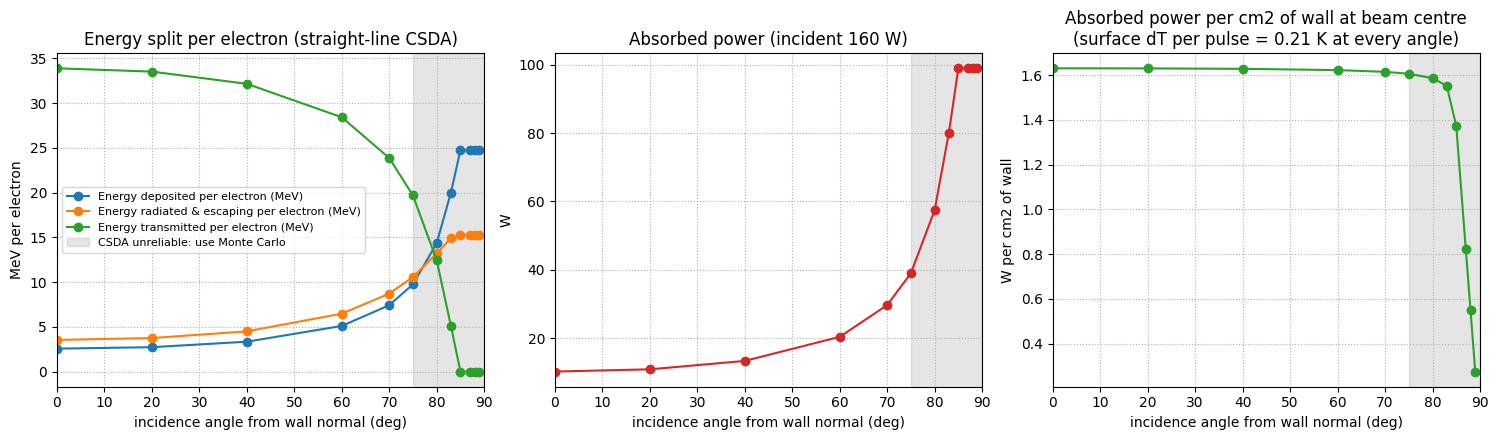

,Path length in wall (mm),Electron stopped in wall,Energy deposited per electron (MeV),Absorbed power (W),Peak absorbed power density (W/cm2),Adiabatic temperature rise per macropulse (K)
Incidence from normal (deg),,,,,,
0,2,False,2.562,10.25,1.631,0.2074
20,2.128,False,2.725,10.9,1.63,0.2074
40,2.611,False,3.339,13.36,1.628,0.2074
60,4,False,5.098,20.39,1.623,0.2074
70,5.848,False,7.417,29.67,1.615,0.2074
75,7.727,False,9.749,39,1.606,0.2074
80,11.52,False,14.35,57.4,1.586,0.2074
83,16.41,False,20.01,80.04,1.552,0.2074
85,22.95,True,24.73,98.93,1.372,0.2074


In [8]:
import warnings
angles = np.array([0, 20, 40, 60, 70, 75, 80, 83, 85, 87, 88, 89])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # grazing-incidence caveat is stated above and shaded in the plots
    rows = [beam_pipe_heating(wall_beam, "Stainless Steel", wall_thickness_m=2e-3, incidence_deg=a) for a in angles]
ang = pd.DataFrame(rows).set_index("Incidence from normal (deg)")
dT_pulse = ang["Adiabatic temperature rise per macropulse (K)"].iloc[0]  # identical at every angle

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ang[["Energy deposited per electron (MeV)", "Energy radiated & escaping per electron (MeV)",
     "Energy transmitted per electron (MeV)"]].plot(ax=axes[0], marker="o")
axes[0].set_ylabel("MeV per electron"); axes[0].set_title("Energy split per electron (straight-line CSDA)")
ang["Absorbed power (W)"].plot(ax=axes[1], marker="o", color="C3")
axes[1].set_ylabel("W"); axes[1].set_title(f"Absorbed power (incident {wall_beam.P_avg_W:.0f} W)")
ang["Peak absorbed power density (W/cm2)"].plot(ax=axes[2], marker="o", color="C2")
axes[2].set_ylabel("W per cm2 of wall")
axes[2].set_title(f"Absorbed power per cm2 of wall at beam centre\n(surface dT per pulse = {dT_pulse:.2f} K at every angle)")
for ax in axes:
    ax.axvspan(bu.GRAZING_WARN_DEG, 90, color="grey", alpha=0.2, label="CSDA unreliable: use Monte Carlo")
    ax.set_xlim(0, 90); ax.grid(True, ls=":"); ax.set_xlabel("incidence angle from wall normal (deg)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
ang[["Path length in wall (mm)", "Electron stopped in wall", "Energy deposited per electron (MeV)",
     "Absorbed power (W)", "Peak absorbed power density (W/cm2)", "Adiabatic temperature rise per macropulse (K)"]]

### Where does the energy go as a function of beam energy?

For a fixed 2 mm wall at normal incidence an electron is fully stopped only below about 2.3 MeV, where the CSDA range in stainless steel equals the wall thickness, and there almost all of its energy heats the wall. Above that the wall is thinner than the range and the transition is quick: half of the energy is already transmitted at 5 MeV (range 4 mm), only about a quarter is deposited at 10 MeV, and at 40 MeV the wall takes 6 % (the "2 mm wall, normal" column above). The bremsstrahlung fraction produced in the wall grows slowly with energy and stays below 10 % for a 2 mm wall.

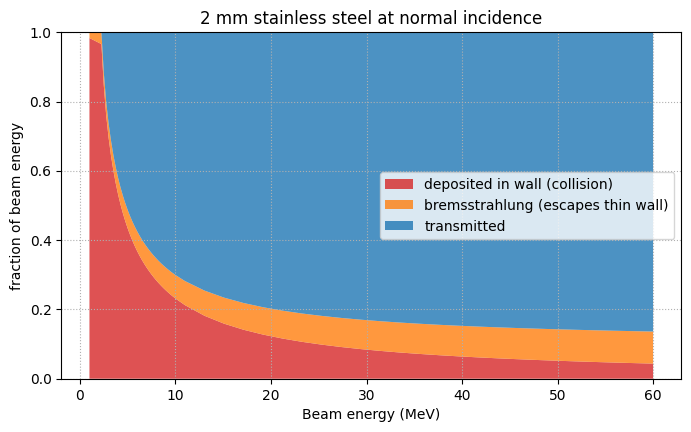

In [9]:
energies = np.concatenate([np.linspace(1, 10, 37), np.linspace(11, 60, 25)])  # fine below 10 MeV to resolve the knee
split = pd.DataFrame([bu.slab_energy_balance(E, "Stainless Steel", 0.2) for E in energies], index=energies)
frac = split[["collision", "radiative", "transmitted"]].div(energies, axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stackplot(energies, frac["collision"], frac["radiative"], frac["transmitted"],
             labels=["deposited in wall (collision)", "bremsstrahlung (escapes thin wall)", "transmitted"],
             colors=["C3", "C1", "C0"], alpha=0.8)
ax.set_xlabel("Beam energy (MeV)"); ax.set_ylabel("fraction of beam energy")
ax.set_title("2 mm stainless steel at normal incidence"); ax.set_ylim(0, 1); ax.legend(loc="center right")
ax.grid(True, ls=":"); plt.show()

### Parameter scan: absorbed power and heating vs energy, current, pulse length and repetition rate

`scan_beam_pipe` evaluates `beam_pipe_heating` on a grid and `plot_scan_grid` shows one panel per (repetition rate, pulse length) with one line per macropulse current. The example keeps the 5 mm × 20 mm footprint and the 2 mm wall at 80°, the grazing-pipe case of this section, which lies inside the shaded region of the previous plots: the absorbed power and absorbed power density are straight-line (CSDA) upper bounds. At 80° the 11.5 mm path exceeds the CSDA range below about 17 MeV, so the three lowest energies are reported as fully stopped and the steep rise of the absorbed-power curves up to that energy is the $E(1-Y)$ ceiling discussed above, not a prediction. The surface $\Delta T$ and mean-heating-rate rows do not depend on the angle and are unaffected. The module's warning is silenced here as in the angle sweep.

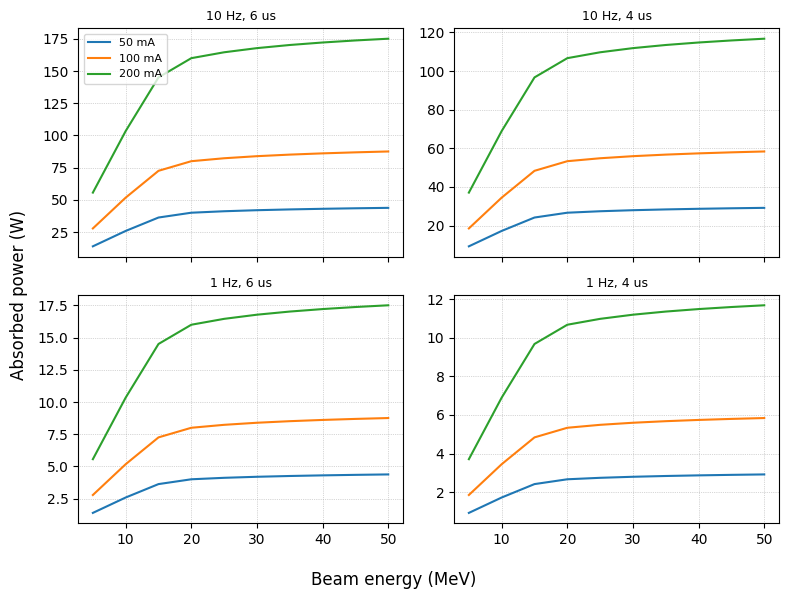

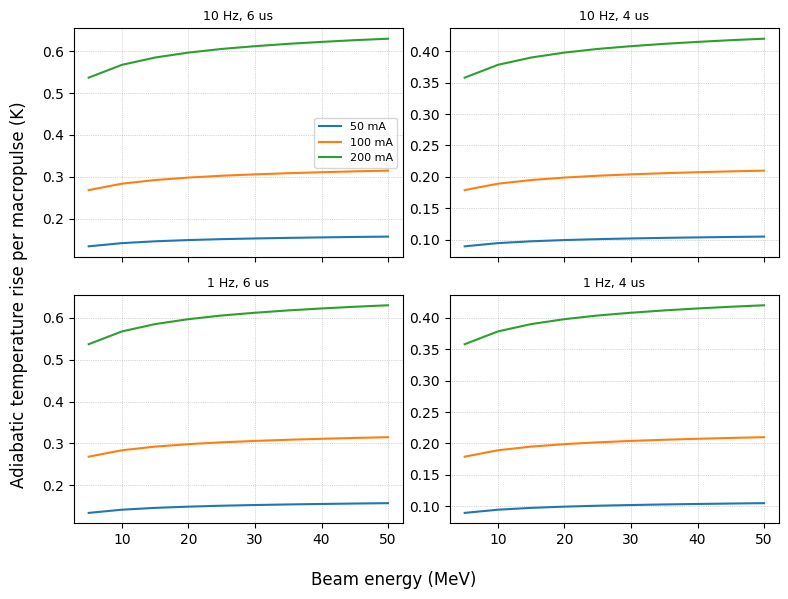

,Beam Current (mA),Pulse Duration (us),Repetition Rate (Hz),Absorbed power (W),Peak absorbed power density (W/cm2),Adiabatic temperature rise per macropulse (K),Mean heating rate without conduction (K/s)
108,50,4,1,2.919,0.08067,0.105,0.105
109,100,4,1,5.838,0.1613,0.2099,0.2099
110,200,4,1,11.68,0.3227,0.4198,0.4198
111,50,6,1,4.379,0.121,0.1574,0.1574
112,100,6,1,8.757,0.242,0.3149,0.3149
113,200,6,1,17.51,0.484,0.6297,0.6297
114,50,4,10,29.19,0.8067,0.105,1.05
115,100,4,10,58.38,1.613,0.2099,2.099
116,200,4,10,116.8,3.227,0.4198,4.198
117,50,6,10,43.79,1.21,0.1574,1.574


In [10]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # grazing-incidence caveat is stated in the text above
    df_pipe = scan_beam_pipe(np.linspace(5, 50, 10), [0.05, 0.10, 0.20], [4e-6, 6e-6], [1.0, 10.0], wall_beam,
                             material="Stainless Steel", wall_thickness_m=2e-3, incidence_deg=80)
bu.plot_scan_grid(df_pipe, "Absorbed power (W)")
bu.plot_scan_grid(df_pipe, "Adiabatic temperature rise per macropulse (K)")
df_pipe[df_pipe["Energy (MeV)"] == 50][["Beam Current (mA)", "Pulse Duration (us)", "Repetition Rate (Hz)",
                                        "Absorbed power (W)", "Peak absorbed power density (W/cm2)",
                                        "Adiabatic temperature rise per macropulse (K)",
                                        "Mean heating rate without conduction (K/s)"]]

## 4. Case B: FLASH dose in a water or skin target

`flash_dose(beam, material, prescription_Gy, target_thickness_m)`

For a target thin compared with the range, the dose at the beam centre and target entrance is the mass collision stopping power times the fluence:

$$D\,[\mathrm{Gy}] = 1.602\times10^{-10}\;\frac{S_{col}}{\rho}\,[\mathrm{MeV\,cm^2/g}]\;\Phi_{peak}\,[\mathrm{cm^{-2}}]$$

(1 MeV/g = 1.602 × 10⁻¹³ J / 10⁻³ kg = 1.602 × 10⁻¹⁰ Gy). The function reports the dose per macropulse and per bunch, the dose rate *inside* the macropulse ($D/T$), the mean dose rate over many pulses ($D f_{rep}$), the number of macropulses and the time needed for the prescription, the charge needed, and the effective spot area that would deliver the prescription in exactly one macropulse.

Commonly quoted FLASH conditions (Favaudon et al., 2014, and later work) are a mean dose rate above about 40 Gy/s, a total delivery time below about 100-200 ms and typically 10 Gy or more in one fraction. The nominal beam exceeds these by orders of magnitude, so the engineering question is dose *control*: spot size, macropulse length, current and collimation.

The skin entry uses the ICRP skin composition ($\rho$ = 1.1 g/cm³, $I$ = 72.7 eV); its mass collision stopping power is about 1 % below that of water.

In [11]:
flash = {
    "Water, nominal beam": flash_dose(beam, "Water", prescription_Gy=10.0, target_thickness_m=0.02),
    "Skin, nominal beam":  flash_dose(beam, "Skin",  prescription_Gy=10.0, target_thickness_m=0.02),
    "Water, 20 MeV":       flash_dose(Beam(20.0, 0.1, 4e-6, 10.0, 1e-3, 10e-3), "Water", 10.0, 0.02),
}
pd.DataFrame(flash)

,"Water, nominal beam","Skin, nominal beam","Water, 20 MeV"
Material,Water,Skin,Water
Energy (MeV),40,40,20
S_col/rho (MeV cm2/g),2.118,2.09,2.046
CSDA range (cm),16.65,15.4,9.32
Peak fluence per macropulse (1/cm2),3.973e+12,3.973e+12,3.973e+12
Dose per macropulse (Gy),1348,1331,1303
Dose per bunch (Gy),0.118,0.1165,0.114
Dose rate in macropulse (Gy/s),3.371e+08,3.326e+08,3.256e+08
Mean dose rate (Gy/s),1.348e+04,1.331e+04,1.303e+04
Prescription (Gy),10,10,10


### Depth-dose along the beam axis

`depth_dose` slows the electron down along the CSDA path and evaluates $S_{col}$ at the local energy, with the fluence held constant. Inside a thin target the curve is flat to a few percent and slopes slightly *downward*: above the stopping-power minimum near 1.7 MeV, $S_{col}/\rho$ increases with energy (the relativistic rise in the table of Section 1: 2.12 MeV cm²/g at 40 MeV, 1.82 at 2 MeV), so it decreases as the electron loses energy, by about 1 % over the first 2 cm at 40 MeV and 3 % at 10 MeV. The sharp rise in the last few millimetres before the CSDA range is $S_{col}$ growing as $E \to 0$; it is an artefact of the CSDA picture and is clipped in the plot. Near the end of the range the CSDA curve is **not** realistic. Two effects compete. Multiple scattering shortens the straight-line penetration (the detour factor), while range straggling lets many electrons travel further than the mean-loss path; at these energies the straggling is dominated by rare but large bremsstrahlung losses, which the CSDA treats as a continuous average. In water the second effect wins above about 10 MeV: the practical range $R_p$ from the ICRU-35 range-energy relation ($E_0 = 0.22 + 1.98\,R_p + 0.0025\,R_p^2$, $R_p$ in cm) is about 4.9, 9.9 and 19.6 cm at 10, 20 and 40 MeV against CSDA ranges of 5.0, 9.3 and 16.6 cm. The real fall-off is gradual, starting well before the CSDA range and ending in a bremsstrahlung tail beyond it. In heavier materials and at a few MeV the detour factor dominates and the penetration is shorter than the CSDA range. Use the CSDA curve only for depths well inside the range.

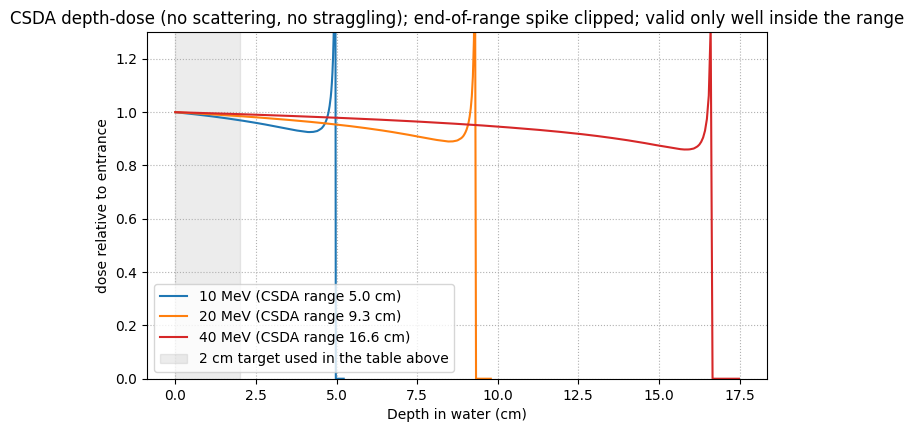

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for E, c in [(10, "C0"), (20, "C1"), (40, "C3")]:
    b = Beam(E, 0.1, 4e-6, 10.0, 1e-3, 10e-3)
    dd = depth_dose(b, "Water", normalise=True)
    ax.plot(dd["Depth (cm)"], dd["Relative dose"], color=c, label=f"{E} MeV (CSDA range {bu.csda_range(E, 'Water'):.1f} cm)")
ax.axvspan(0, 2, color="grey", alpha=0.15, label="2 cm target used in the table above")  # keep well below the range of the lowest energy plotted
ax.set_xlabel("Depth in water (cm)"); ax.set_ylabel("dose relative to entrance")
ax.set_title("CSDA depth-dose (no scattering, no straggling); end-of-range spike clipped; valid only well inside the range")
ax.set_ylim(0, 1.3); ax.grid(True, ls=":"); ax.legend(); plt.show()

### Controlling the dose with the spot size

Dose per macropulse scales as $1/(\sigma_x\sigma_y)$. Scaling both RMS sizes by the same factor $k$ (keeping the 1:10 aspect ratio) shows how far the beam must be defocused to bring one macropulse down to a 10 Gy prescription.

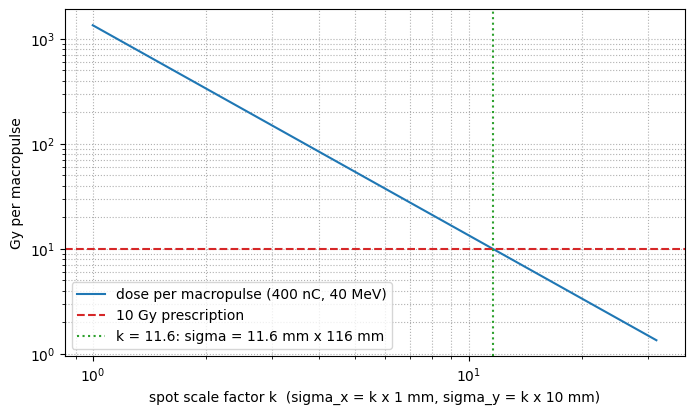

One 400 nC macropulse delivers 10 Gy when sigma_x = 11.6 mm and sigma_y = 116 mm (effective area 85 cm2).


In [13]:
k = np.logspace(0, 1.5, 40)
dose_k = np.array([flash_dose(Beam(40.0, 0.1, 4e-6, 10.0, 1e-3 * ki, 10e-3 * ki), "Water")["Dose per macropulse (Gy)"] for ki in k])
k_10Gy = math.sqrt(flash_dose(beam, "Water", 10.0)["Effective area for prescription in one pulse (cm2)"] / beam.effective_area_cm2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(k * 1.0, dose_k, label="dose per macropulse (400 nC, 40 MeV)")
ax.axhline(10, color="C3", ls="--", label="10 Gy prescription")
ax.axvline(k_10Gy, color="C2", ls=":", label=f"k = {k_10Gy:.1f}: sigma = {k_10Gy:.1f} mm x {10*k_10Gy:.0f} mm")
ax.set_xlabel("spot scale factor k  (sigma_x = k x 1 mm, sigma_y = k x 10 mm)"); ax.set_ylabel("Gy per macropulse")
ax.grid(True, which="both", ls=":"); ax.legend(); plt.show()
print(f"One 400 nC macropulse delivers 10 Gy when sigma_x = {k_10Gy:.1f} mm and sigma_y = {10*k_10Gy:.0f} mm "
      f"(effective area {beam.effective_area_cm2 * k_10Gy**2:.0f} cm2).")

### Parameter scan: dose per macropulse and mean dose rate

Same grid layout as for the beam pipe. Because $S_{col}/\rho$ is almost flat, the dose per macropulse is nearly independent of energy and simply proportional to $I\,T$; the mean dose rate adds the factor $f_{rep}$.

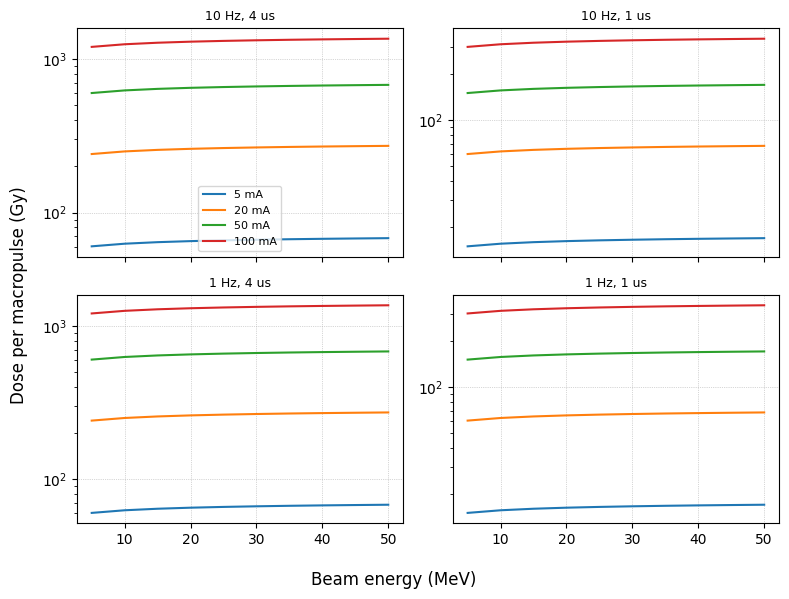

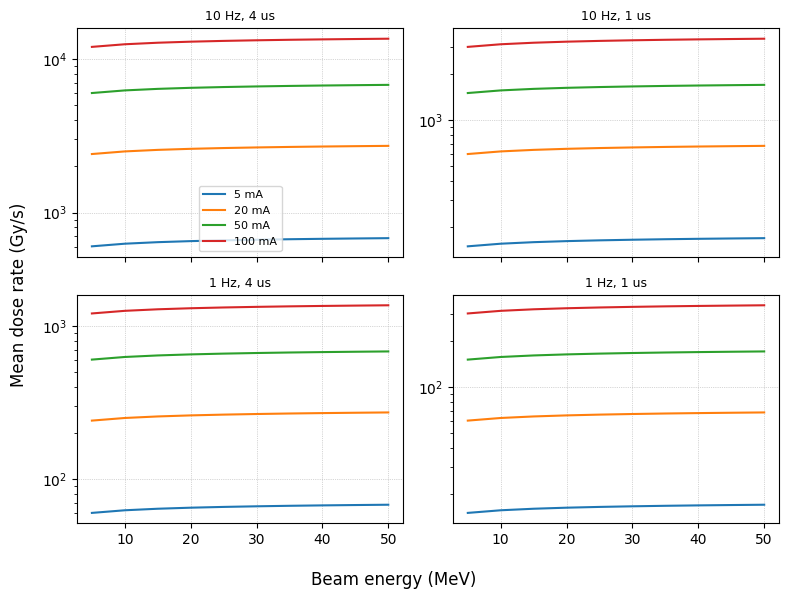

In [14]:
df_flash = scan_flash(np.linspace(5, 50, 10), [0.005, 0.02, 0.05, 0.10], [1e-6, 4e-6], [1.0, 10.0], beam, material="Water")
bu.plot_scan_grid(df_flash, "Dose per macropulse (Gy)", logy=True)
bu.plot_scan_grid(df_flash, "Mean dose rate (Gy/s)", logy=True);

### Delivery options for a 10 Gy prescription

A few ways to bring the dose per macropulse to the order of the prescription. Two separate checks are shown. The **dose-rate criteria** column tests mean dose rate ≥ 40 Gy/s and delivery time ≤ 200 ms for the number of macropulses needed. The **single pulse overshoots** column flags configurations where one macropulse already exceeds the prescription, so the dose cannot be controlled unless the macropulse is shortened or gated at the bunch level. A workable configuration needs the first to be true and the second false. The mean dose rate column is $D\,f_{rep}$, the rate of a long pulse train; a delivery that ends after two or three pulses has a somewhat higher effective rate.

In [15]:
options = {
    "nominal: 100 mA, 4 us, 1x10 mm":            Beam(40.0, 0.100, 4e-6,   10.0, 1e-3,  10e-3),
    "defocus to 12x120 mm":                      Beam(40.0, 0.100, 4e-6,   10.0, 12e-3, 120e-3),
    "10 mA, 0.5 us, 3x30 mm, 10 Hz":             Beam(40.0, 0.010, 0.5e-6, 10.0, 3e-3,  30e-3),
    "10 mA, 0.5 us, 3x30 mm, 100 Hz":            Beam(40.0, 0.010, 0.5e-6, 100.0, 3e-3, 30e-3),
    "5 mA, 1 us, round 5 mm, 10 Hz":             Beam(40.0, 0.005, 1e-6,   10.0, 5e-3,  5e-3),
    "20 MeV, 20 mA, 2 us, 5x20 mm, 50 Hz":       Beam(20.0, 0.020, 2e-6,   50.0, 5e-3,  20e-3),
}
rows = []
for name, b in options.items():
    r = flash_dose(b, "Water", prescription_Gy=10.0)
    rows.append({
        "configuration": name,
        "charge per macropulse (nC)": b.Q_macropulse_C * 1e9,
        "dose per macropulse (Gy)": r["Dose per macropulse (Gy)"],
        "dose per bunch (mGy)": r["Dose per bunch (Gy)"] * 1e3,
        "macropulses for 10 Gy": r["Macropulses for prescription"],
        "delivery time (ms)": r["Delivery time for prescription (s)"] * 1e3,
        "mean dose rate (Gy/s)": r["Mean dose rate (Gy/s)"],
        "in-pulse dose rate (Gy/s)": r["Dose rate in macropulse (Gy/s)"],
        "dose-rate criteria met": (r["Mean dose rate (Gy/s)"] >= 40) and (r["Delivery time for prescription (s)"] <= 0.2),
        "single pulse overshoots": r["Macropulses for prescription"] < 1,
    })
pd.DataFrame(rows).set_index("configuration")

,charge per macropulse (nC),dose per macropulse (Gy),dose per bunch (mGy),macropulses for 10 Gy,delivery time (ms),mean dose rate (Gy/s),in-pulse dose rate (Gy/s),dose-rate criteria met,single pulse overshoots
configuration,,,,,,,,,
"nominal: 100 mA, 4 us, 1x10 mm",400,1348,118,0.007416,0.004,1.348e+04,3.371e+08,True,True
defocus to 12x120 mm,400,9.364,0.8196,1.068,100,93.64,2.341e+06,True,False
"10 mA, 0.5 us, 3x30 mm, 10 Hz",5,1.873,1.311,5.34,500,18.73,3.745e+06,False,False
"10 mA, 0.5 us, 3x30 mm, 100 Hz",5,1.873,1.311,5.34,50,187.3,3.745e+06,True,False
"5 mA, 1 us, round 5 mm, 10 Hz",5,6.742,2.361,1.483,100,67.42,6.742e+06,True,False
"20 MeV, 20 mA, 2 us, 5x20 mm, 50 Hz",40,13.03,2.28,0.7677,0.002,651.3,6.513e+06,True,True


## 5. Summary and limits

* **Beam pipe (Case A).** The relevant quantities are the absorbed power (for cooling) and the peak surface energy density per macropulse (for thermal shock). Above a few MeV a 2 mm stainless wall is thin compared with the range at normal incidence; most of the energy is transmitted or radiated. The surface temperature rise per pulse is set by $\Phi_{peak}\,S_{col}$ alone and does not depend on the incidence angle; the absorbed power per cm² of wall falls as $\cos\theta$ once the electron is stopped. At grazing incidence (above about 75°) the straight-line model overestimates the deposited energy because multiple scattering turns a large fraction of the electrons back out of the wall, or through it, before they stop (roughly a third reflected at 80°, half at 85° and two thirds at 88° by the estimate in Section 3); those angles need a Monte Carlo calculation.
* **FLASH (Case B).** Dose per macropulse is $1.6\times10^{-10}\,(S_{col}/\rho)\,\Phi_{peak}$ and is almost independent of energy above a few MeV. The nominal macropulse delivers of order 1000 Gy at the beam centre; a 10 Gy prescription needs about 3 nC at the nominal spot, or a spot about 12 times larger in each plane. FLASH dose-rate criteria are met trivially; dose control is the design problem.
* **Model limits.** CSDA transport (no scattering, straggling, lateral spread or backscatter), unreliable at grazing incidence; the depth-dose curve is only valid well inside the range; heating is adiabatic per pulse with no conduction; bremsstrahlung re-absorption is a user parameter. Stainless steel is a Bragg-additivity mixture of the Fe, Cr and Ni ESTAR tables.
* **Tests.** `backend/test/test_beam_utility.py` checks the tables against ESTAR grid points, energy conservation in the slab transport and the dose formula against a hand-computed case.